# LeetCode #340: Longest Substring with At Most K Distinct Characters

https://leetcode.com/problems/longest-substring-with-at-most-k-distinct-characters/

## Comparison of Approaches
| Approach | Time | Space |
|---|---|---|
| Sliding Window + HashMap ★ | O(n) | O(k) |
| Brute Force | O(n²) | O(n) |

## Understanding the Methods
### Sliding Window + HashMap (Optimal)
Maintain a window [left, right] and a hash map counting character frequencies. Expand right to include new characters. When distinct characters exceed k, shrink from the left until we have at most k distinct characters. Track the maximum window length throughout.

### Brute Force
Check all substrings and count distinct characters in each. O(n²) substrings, each needing O(n) to process.

## Solutions

### C#

In [ ]:
public class Solution {
    public int LengthOfLongestSubstringKDistinct(string s, int k) {
        var count = new Dictionary<char, int>();
        int left = 0, maxLen = 0;
        for (int right = 0; right < s.Length; right++) {
            count[s[right]] = count.GetValueOrDefault(s[right]) + 1;
            while (count.Count > k) {
                count[s[left]]--;
                if (count[s[left]] == 0) count.Remove(s[left]);
                left++;
            }
            maxLen = Math.Max(maxLen, right - left + 1);
        }
        return maxLen;
    }
}

### Python

In [ ]:
from collections import defaultdict

class Solution:
    def lengthOfLongestSubstringKDistinct(self, s: str, k: int) -> int:
        count = defaultdict(int)
        left = max_len = 0
        for right, c in enumerate(s):
            count[c] += 1
            while len(count) > k:
                count[s[left]] -= 1
                if count[s[left]] == 0:
                    del count[s[left]]
                left += 1
            max_len = max(max_len, right - left + 1)
        return max_len

### Go

In [ ]:
func lengthOfLongestSubstringKDistinct(s string, k int) int {
    count := map[byte]int{}
    left, maxLen := 0, 0
    for right := 0; right < len(s); right++ {
        count[s[right]]++
        for len(count) > k {
            count[s[left]]--
            if count[s[left]] == 0 {
                delete(count, s[left])
            }
            left++
        }
        if right-left+1 > maxLen {
            maxLen = right - left + 1
        }
    }
    return maxLen
}

### Rust

In [ ]:
use std::collections::HashMap;

impl Solution {
    pub fn length_of_longest_substring_k_distinct(s: String, k: i32) -> i32 {
        let k = k as usize;
        let bytes = s.as_bytes();
        let mut count: HashMap<u8, usize> = HashMap::new();
        let (mut left, mut max_len) = (0usize, 0usize);
        for right in 0..bytes.len() {
            *count.entry(bytes[right]).or_insert(0) += 1;
            while count.len() > k {
                let c = bytes[left];
                *count.get_mut(&c).unwrap() -= 1;
                if count[&c] == 0 {
                    count.remove(&c);
                }
                left += 1;
            }
            max_len = max_len.max(right - left + 1);
        }
        max_len as i32
    }
}

## Example Scenarios

### 1. Common Case — Window Slides Past a Third Character
**Input:** `s = "eceba", k = 2`
Expand right adding chars to a frequency map. The window `"ece"` uses $\{e,c\}$ (2 distinct). When `b` arrives the map hits 3 distinct, so shrink from the left until at most $k$ remain. The best window seen is `"ece"`, length 3.
**Output:** `3`

### 2. Slightly Complex — Repeated Shrinking
**Input:** `s = "aababcbc", k = 2`
The window grows to `"aabab"` on $\{a,b\}$ (length 5). Once `c` enters, distinct becomes 3 and the left edge advances, dropping `a`'s until the window is valid again. The maximum length recorded is 5.
**Output:** `5`

### 3. Edge Case: Time Factor — k ≥ Alphabet, No Shrinking
**Input:** `s = "abc", k = 5`
Since $k$ exceeds the number of distinct characters, the `while len(count) > k` shrink loop never runs. `right` sweeps once across the string in a clean $O(n)$ pass and the whole string stays valid.
**Output:** `3`

### 4. Edge Case: Space Factor — k = 1 Tiny Map
**Input:** `s = "aa", k = 1`
Only one distinct character is ever allowed, so the frequency map holds at most $k = 1$ entry — $O(k)$ space. The entire `"aa"` is a valid window of length 2.
**Output:** `2`

### 5. Almost-Impossible but Plausible — k = 0
**Input:** `s = "abc", k = 0`
No character may be kept. The moment `right` adds the first char, `len(count) = 1 > 0` triggers the shrink loop, which immediately pushes `left` past `right`, so every window has length 0.
**Output:** `0`


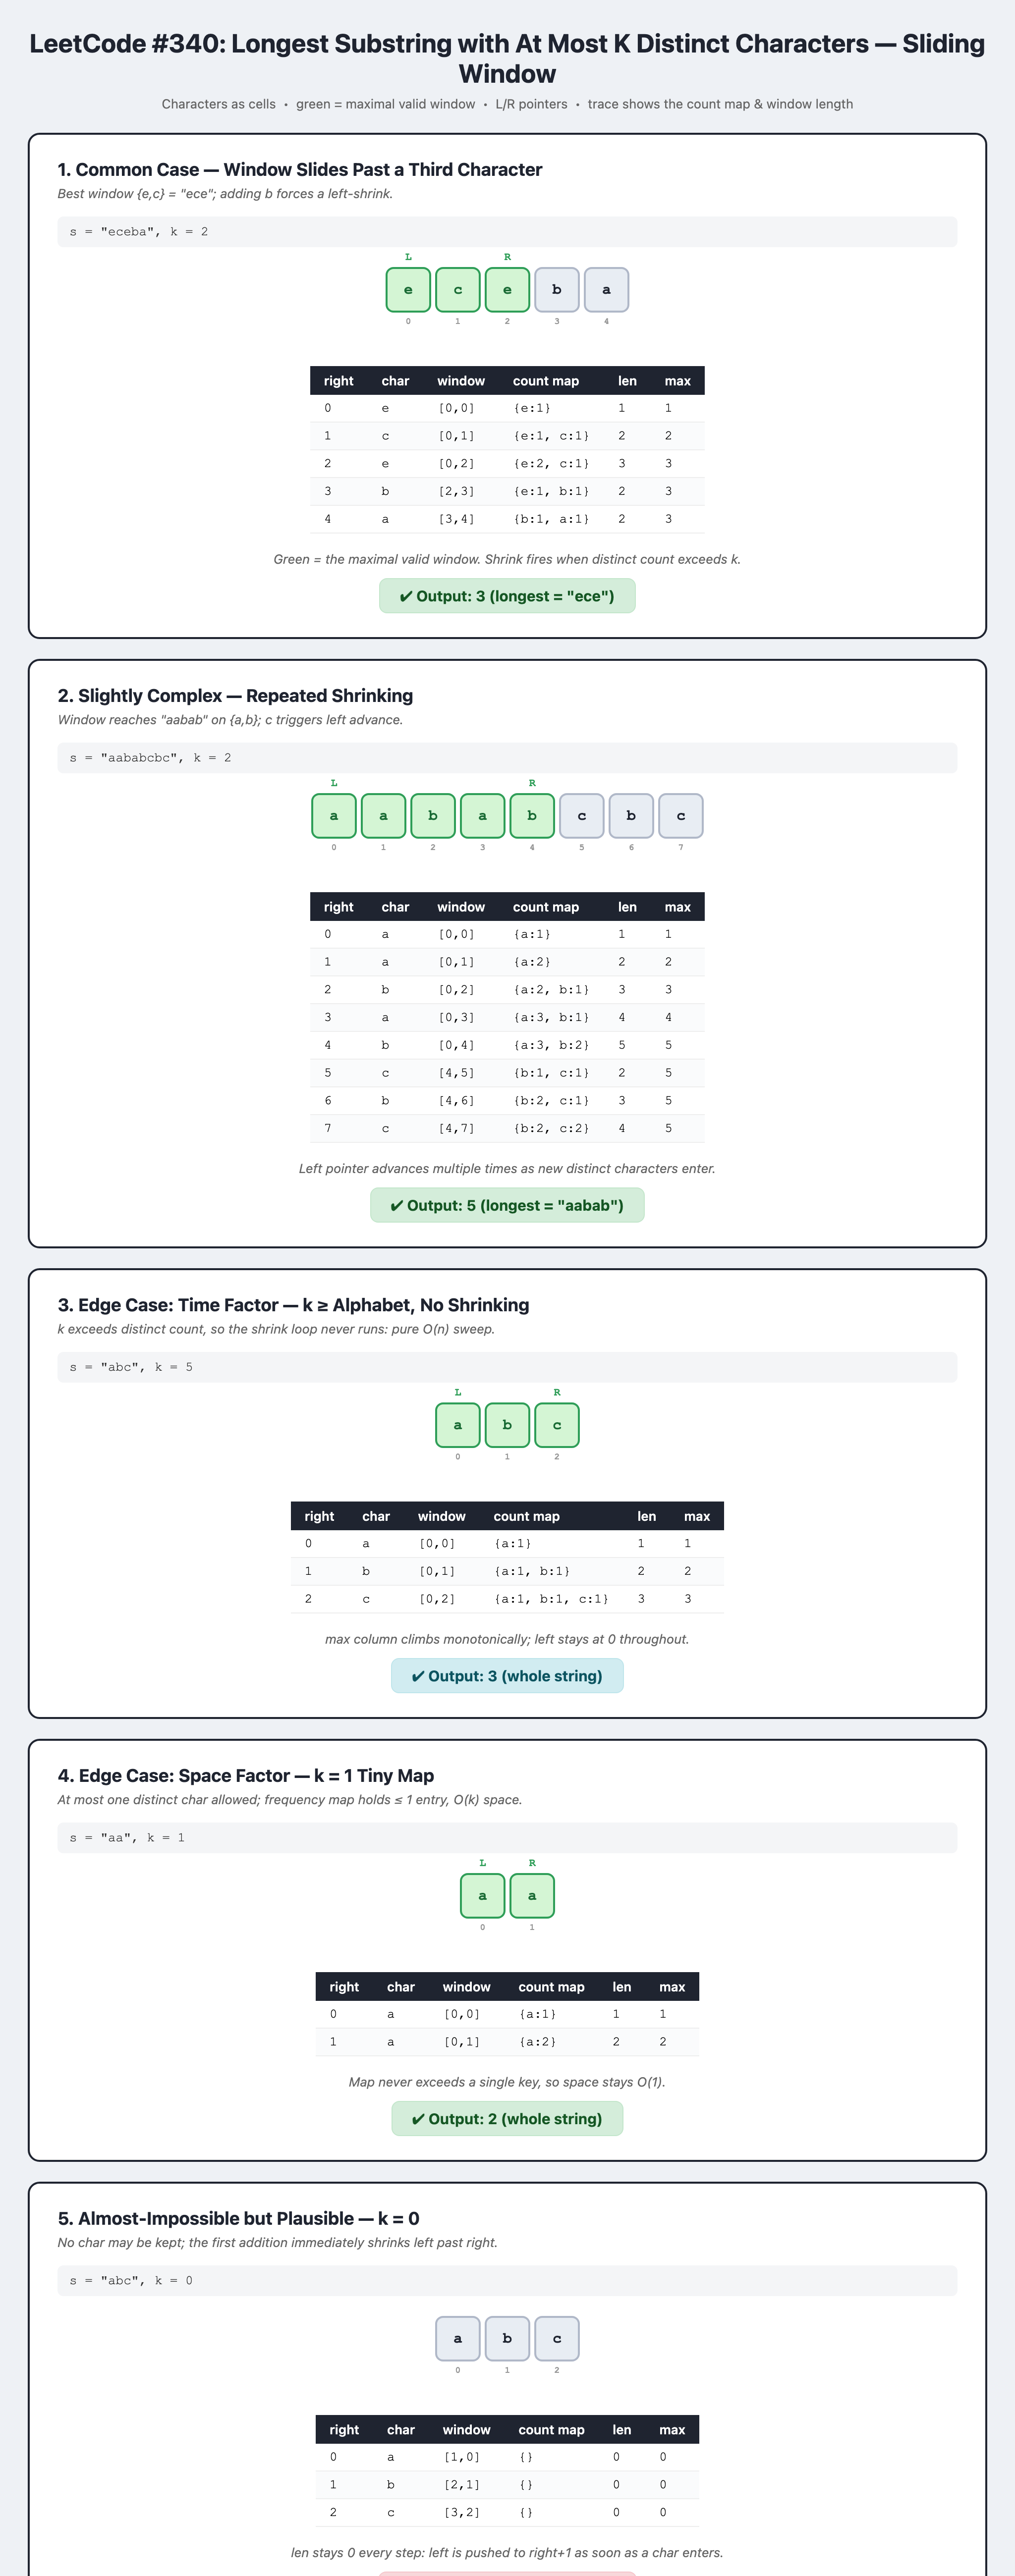